**HW1 EDA**

In [3]:
from pathlib import Path
import json

import matplotlib.pyplot as plt 
import pandas as pd 
import seaborn as sns

DATA_PATH = Path("data/hw1_train.jsonl")
FIG_DIR = Path("eda_figures")
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

данные в файле фората jsonl, поэтому нужно сейчас распарсить данные построчно

In [4]:
records = [] #внутри listы

with open(DATA_PATH, encoding="utf-8") as fh:
    for line in fh:
        line = line.strip()
        if not line:
            continue
        records.append(json.loads(line))

len(records)

10000

длина получилась как заявленная. посмотрим на пример диалога сразу



In [5]:
import pprint

sample = records[0]

short_turns = [
    {
        **turn,"text": (turn["text"][:120] + "…") if len(turn["text"]) > 120 else turn["text"],
    }
    for turn in sample["turns"][:6]
]

pprint.pp({**sample, "turns": short_turns}, width=100)

{'dialog_id': 'd094012177e',
 'language': 'en',
 'n_user_turns': 7,
 'turns': [{'role': 'user',
            'text': 'it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus '
                    'we can possibly use in this concept and int…'},
           {'role': 'assistant',
            'text': 'Introducing scientific terms from astrophysics or any other scientific '
                    'discipline to the given equation "1+1=2+1+1=?" ma…'},
           {'role': 'user',
            'text': "let's then try to mix it all together with some quantum physics terms in "
                    'use.'},
           {'role': 'assistant',
            'text': 'Introducing quantum physics terms into the given equation "1+1=2+1+1=?" can '
                    "be an interesting exercise, although it's im…"},
           {'role': 'user',
            'text': 'this could result in some extremely large unknown sequence in overall '
                    "concept. it's all up to you now, sin

предлагается сформировать условную таблицу диалогов.
один диалог - одна строка таблицы: язык, длины, метки, флаги и прочее. и дальше уже работаем с ней, а не с сырым records


In [6]:
def row_from_dialog(rec: dict) -> dict:
    labels = rec.get("labels") or {}
    turns = rec.get("turns") or []

    user_texts = [t["text"] for t in turns if t["role"] == "user"]
    asst_texts = [t["text"] for t in turns if t["role"] == "assistant"]
    full_text = ''.join(t.get("text") or "" for t in turns)

    return {
        "dialog_id": rec["dialog_id"],
        "language": rec.get("language"),
        "n_user_turns_field": rec.get("n_user_turns"),
        "n_turns": len(turns),
        "n_user": len(user_texts),
        "n_assistant": len(asst_texts),
        "total_chars": len(full_text),
        "user_chars": sum(len(t) for t in user_texts),
        "has_labels": bool(labels),
        "reaction": labels.get("reaction"),
        "task_type": labels.get("task_type"),
        "any_empty": any((t.get("text") or "").strip() == "" for t in turns),
        "has_code": "```" in full_text,
        "user_key": " ".join(user_texts)[:300],
        "first_user": user_texts[0][:120] if user_texts else "",
    }

dialogs = pd.DataFrame([row_from_dialog(r) for r in records])
dialogs.head()# первые 5 строк для проверки

,dialog_id,language,n_user_turns_field,n_turns,n_user,n_assistant,total_chars,user_chars,has_labels,reaction,task_type,any_empty,has_code,user_key,first_user
0,d094012177e,en,7,14,7,7,18945,8453,True,positive,analysis,False,False,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...","it’s like: 1+1=2, but 1+1=2+1+1=? is undefined..."
1,d306fbe61fe,en,8,16,8,8,33533,1278,True,neutral,information_seeking,False,True,Can you help me train a small language model t...,Can you help me train a small language model t...
2,dd6905952c7,en,5,10,5,5,15264,3326,True,neutral,creation,False,False,ask questions about a fictional voice actor i ...,ask questions about a fictional voice actor i ...
3,d767a675896,en,6,12,6,6,10368,1115,True,negative,information_seeking,False,False,Calculate each prompt based off of data and sh...,Calculate each prompt based off of data and sh...
4,d7a6280ce8e,en,8,16,8,8,7902,374,True,negative,information_seeking,False,False,"mass spectrometer, the length of AC rod will i...","mass spectrometer, the length of AC rod will i..."


In [7]:
print("диалогов:", len(dialogs))
print("\nязыки:\n", dialogs["language"].value_counts())
print("\nдоля с labels:", dialogs["has_labels"].mean())
print(
    "n_user_turns совпадает с фактом:",
    (dialogs["n_user_turns_field"] == dialogs["n_user"]).mean(),
)

диалогов: 10000

языки:
 language
en    9929
ru      71
Name: count, dtype: int64

доля с labels: 0.3
n_user_turns совпадает с фактом: 1.0


In [8]:
dialogs[["n_turns", "n_user", "total_chars"]].describe()

,n_turns,n_user,total_chars
count,10000.000000,10000.000000,10000.00000
mean,13.397600,6.698800,12315.57580
std,3.190695,1.595347,8411.34764
min,10.000000,5.000000,181.00000
25%,10.000000,5.000000,6030.75000
50%,12.000000,6.000000,10800.50000
75%,16.000000,8.000000,16916.25000
max,20.000000,10.000000,59794.00000


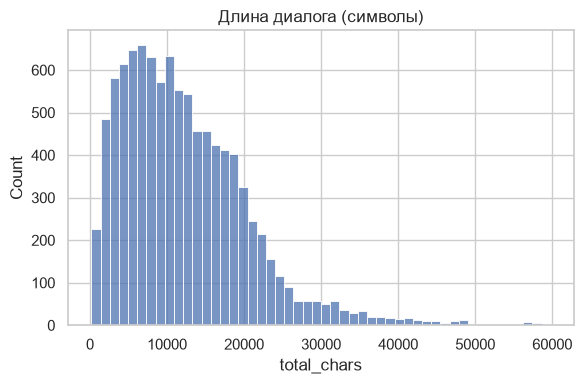

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(dialogs["total_chars"], bins=50, ax=ax)
ax.set_title("Длина диалога (символы)")
fig.tight_layout()
fig.savefig(FIG_DIR / "dialog_length_chars.png", dpi=130)
plt.show()

только размеченные

In [10]:
labeled = dialogs[dialogs["has_labels"]]
labeled["reaction"].value_counts()

reaction
neutral     1774
negative     923
positive     303
Name: count, dtype: int64

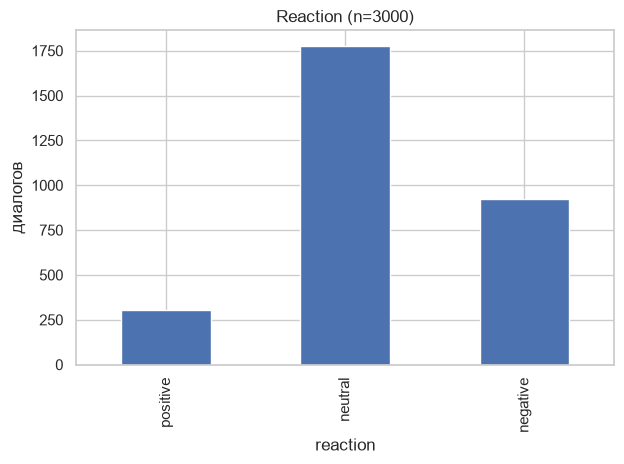

In [11]:
order = ["positive", "neutral", "negative"]
labeled["reaction"].value_counts().reindex(order).plot(kind="bar", title=f"Reaction (n={len(labeled)})")
plt.ylabel("диалогов")
plt.tight_layout()
plt.savefig(FIG_DIR / "reaction_balance.png", dpi=130)
plt.show()

In [12]:
labeled["task_type"].value_counts()


task_type
information_seeking     1831
creation                 944
analysis                 137
open-ended_discovery      88
Name: count, dtype: int64

Рзаметка п каждой реплике пользователя

In [13]:
turn_rows = []

for rec in records:
    labels = rec.get("labels") or {}
    ut = labels.get("user_turns") or []
    user_idx = 0

    for turn in rec.get("turns") or []:
        if turn["role"] != "user":
            continue

        info = ut[user_idx] if user_idx < len(ut) else {}
        turn_rows.append({
            "dialog_id": rec["dialog_id"],
            "turn_index": user_idx,
            "reaction": info.get("reaction"),
            "state": info.get("state"),
            "reaction_reason": info.get("reaction_reason"),
        })
        user_idx += 1

user_turns = pd.DataFrame(turn_rows)
user_turns.head()

,dialog_id,turn_index,reaction,state,reaction_reason
0,d094012177e,0,NaN,continuation,NaN
1,d094012177e,1,neutral,continuation,NaN
2,d094012177e,2,positive,continuation,Humor
3,d094012177e,3,neutral,continuation,NaN
4,d094012177e,4,negative,continuation,Negative_Feedback


сразу же можноо заметить, что у разметки три состояния: есть, нет, частично. где-то не размечено в целом ничего, а где-то есть разметка, например, реакции

In [14]:
print(user_turns["reaction"].value_counts(dropna=False).head())
print(user_turns["state"].value_counts(dropna=False).head(10))
print(user_turns["reaction_reason"].value_counts(dropna=False).head(10))

reaction
NaN         49937
neutral     14099
negative     2416
positive      536
Name: count, dtype: int64
state
NaN                 46937
continuation        10190
newtopic             5690
refinement           2571
feedback             1577
positive_closure       21
revision                2
Name: count, dtype: int64
reaction_reason
NaN                    64045
Insufficient_Detail      853
Revision                 491
Factual_Error            490
Negative_Feedback        283
Gratitude                188
Ignored                  137
Acknowledgment            97
Style                     71
Praise                    69
Name: count, dtype: int64


сравним реакцию на уровне диалога и реакцию на последней юзер-реплике

In [15]:
last = user_turns.sort_values("turn_index").groupby("dialog_id").tail(1)

merged = labeled.merge(
    last[["dialog_id", "reaction"]],
    on="dialog_id",
    suffixes=("_dialog", "_last"),
)

match_rate = (merged["reaction_dialog"] == merged["reaction_last"]).mean()
print(f"совпадение: {match_rate:.3f}")

merged.loc[
    merged["reaction_dialog"] != merged["reaction_last"],
    ["dialog_id", "reaction_dialog", "reaction_last"],
].head(3)

совпадение: 0.809


,dialog_id,reaction_dialog,reaction_last
0,d094012177e,positive,neutral
4,d7a6280ce8e,negative,neutral
6,d6dbef1f003,negative,neutral


дубликаты и мусор

In [16]:
dup = dialogs[dialogs["user_key"].str.len() > 20].duplicated("user_key", keep=False)
print("в группах дубликатов (user_key):", dup.sum())
print("пустых реплик:", dialogs["any_empty"].sum())
print("с код-блоками:", dialogs["has_code"].sum())
print("\nтоп-5 первых user-сообщений:")
print(dialogs["first_user"].value_counts().head())

в группах дубликатов (user_key): 2
пустых реплик: 0
с код-блоками: 2470

топ-5 первых user-сообщений:
first_user
Create a scam-baiting response to the following email, to lure the scammer into a false sense of security by posing as a     4
Create a scam-baiting response to the following email, to keep the scammer in a false sense of security by posing as a p     3
Below is a paragraph from an academic paper.\nPolish the writing to meet the academic style, improve the spelling, gramma    3
use straightforward elastic mechanics (compression/tension, flexure, shear to be based on A_shear = 0.5*A_gross) to get      3
Write a realistic, sensible, plausible and alternate history scenario in the form of a historical documentary book chapt     3
Name: count, dtype: int64
